# Neural Network (MLP classifier)

Feedforward network with ReLU hidden layers and a softmax output, trained with cross-entropy loss.

**Forward:** `a = relu(a_prev @ W + b)` per hidden layer; the last layer outputs logits, then softmax gives class probabilities.

**Backward (backpropagation):** for softmax + cross-entropy the gradient at the logits is simply `(probs - onehot) / n`. Then, layer by layer from the output back:

```
dW = a_prev.T @ dz
db = dz.sum(0)
dz_prev = (dz @ W.T) * (z_prev > 0)     # through the weights, then the ReLU gate
```

Weights use He initialization and are updated by mini-batch gradient descent. `test_model.py` checks the hand-written gradients against finite differences — the standard way to verify backprop.

## Usage

```python
# (the class is defined in the Implementation section below)

net = NeuralNetClassifier(hidden_sizes=(32,), lr=0.1, epochs=50).fit(X_train, y_train)
preds = net.predict(X_test)
probs = net.predict_proba(X_test)
print(net.loss_history_)   # training loss per epoch
```

Scale inputs first (e.g. standardize, or divide pixels by 255).

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class NeuralNetClassifier:
    """Feedforward network: ReLU hidden layers, softmax output, cross-entropy loss,
    backpropagation written by hand, trained with mini-batch gradient descent."""

    def __init__(self, hidden_sizes=(16,), lr=0.1, epochs=100, batch_size=32, random_state=0):
        self.hidden_sizes = hidden_sizes
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.classes_ = None
        self.W, self.b = [], []
        self.loss_history_ = []

    def _init_params(self, n_in, n_out, rng):
        sizes = [n_in, *self.hidden_sizes, n_out]
        # He initialization keeps ReLU activations from shrinking/exploding with depth
        self.W = [rng.normal(0, np.sqrt(2 / a), (a, b)) for a, b in zip(sizes[:-1], sizes[1:])]
        self.b = [np.zeros(b) for b in sizes[1:]]

    def _forward(self, X):
        acts, pre = [X], []  # acts[i] is the input of layer i; pre[i] its pre-activation
        a = X
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            z = a @ W + b
            pre.append(z)
            a = z if i == len(self.W) - 1 else np.maximum(z, 0)  # last layer stays as logits
            acts.append(a)
        e = np.exp(a - a.max(axis=1, keepdims=True))  # subtract max: numerically stable softmax
        return acts, pre, e / e.sum(axis=1, keepdims=True)

    def _loss_and_grads(self, X, Y):
        acts, pre, probs = self._forward(X)
        n = len(X)
        loss = -np.sum(Y * np.log(probs + 1e-12)) / n

        grad_W, grad_b = [None] * len(self.W), [None] * len(self.W)
        dz = (probs - Y) / n  # d(loss)/d(logits) for softmax + cross-entropy
        for i in reversed(range(len(self.W))):
            grad_W[i] = acts[i].T @ dz
            grad_b[i] = dz.sum(axis=0)
            if i > 0:
                dz = (dz @ self.W[i].T) * (pre[i - 1] > 0)  # through weights, then ReLU gate
        return loss, grad_W, grad_b

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_, y_enc = np.unique(y, return_inverse=True)
        Y = np.eye(len(self.classes_))[y_enc]  # one-hot targets

        rng = np.random.default_rng(self.random_state)
        self._init_params(X.shape[1], len(self.classes_), rng)
        self.loss_history_ = []

        for _ in range(self.epochs):
            order = rng.permutation(len(X))
            for start in range(0, len(X), self.batch_size):
                idx = order[start : start + self.batch_size]
                _, grad_W, grad_b = self._loss_and_grads(X[idx], Y[idx])
                for i in range(len(self.W)):
                    self.W[i] -= self.lr * grad_W[i]
                    self.b[i] -= self.lr * grad_b[i]
            self.loss_history_.append(self._loss_and_grads(X, Y)[0])
        return self

    def predict_proba(self, X):
        return self._forward(np.asarray(X, dtype=float))[2]

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

## See it work

### 1. The loss curve

`loss_history_` holds the cross-entropy after every epoch. Training is stochastic gradient descent on mini-batches with backpropagation (the chain rule layer by layer). Different learning rates give different speeds, and too large a rate gets noisy.

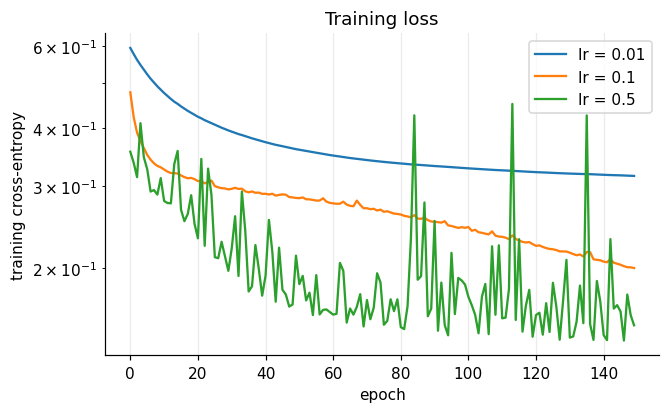

In [3]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
def plot_boundary(ax, model, X, y, cmap="coolwarm", n=150, pad=0.5):
    """Colour the plane by the model's predicted class, then draw the data on top."""
    gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, n), np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, n))
    pred = np.asarray(model.predict(np.c_[gx.ravel(), gy.ravel()])).reshape(gx.shape)
    K = len(np.unique(y))
    ax.contourf(gx, gy, pred, alpha=0.25, cmap=cmap, levels=np.arange(-0.5, K + 0.5) if K > 2 else [-0.5, 0.5, 1.5])
    ax.scatter(*X.T, c=y, cmap=cmap, s=14, edgecolor="k", linewidth=0.3)

Xm, ym = make_moons(n_samples=400, noise=0.25, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(Xm, ym, test_size=0.5, random_state=0)
acc = lambda m, X, y: (m.predict(X) == y).mean()
plt.figure(figsize=(6.5, 3.8))
for lr in (0.01, 0.1, 0.5):
    net = NeuralNetClassifier(hidden_sizes=(16,), lr=lr, epochs=150, random_state=0).fit(Xtr, ytr)
    plt.plot(net.loss_history_, label=f"lr = {lr}")
plt.xlabel("epoch"); plt.ylabel("training cross-entropy"); plt.yscale("log"); plt.legend(); plt.title("Training loss"); plt.show()

### 2. Capacity: hidden units shape the boundary

With no hidden layer a network is just softmax regression (a straight line). A couple of ReLU units can bend the line; more units give a smoother, more flexible boundary.

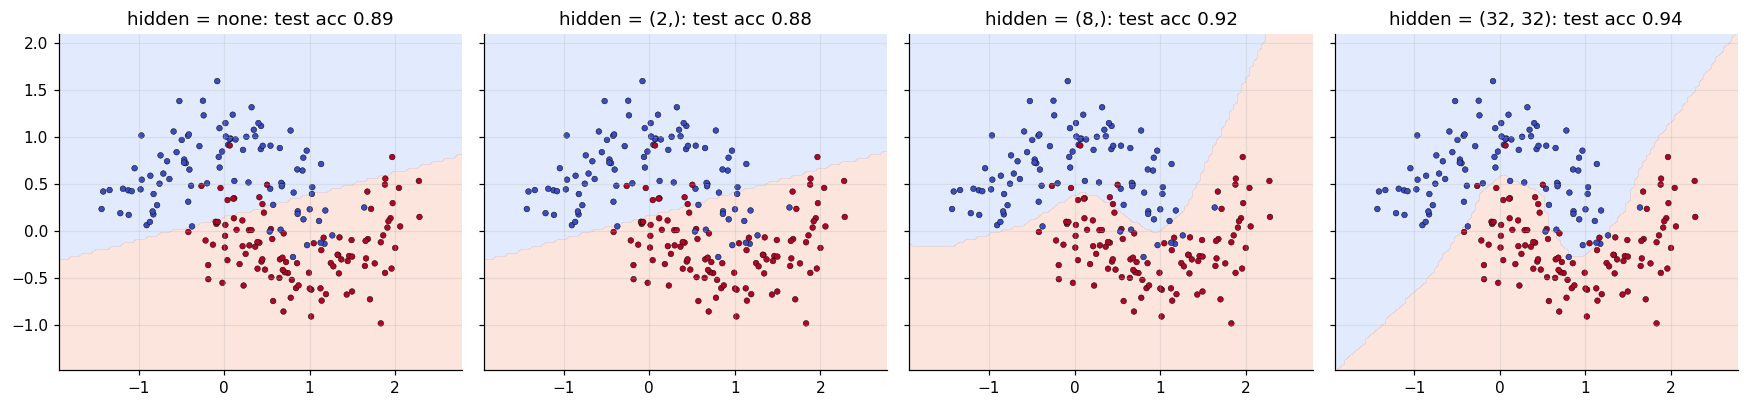

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, hs in zip(axes, [(), (2,), (8,), (32, 32)]):
    net = NeuralNetClassifier(hidden_sizes=hs, lr=0.1, epochs=300, random_state=0).fit(Xtr, ytr)
    plot_boundary(ax, net, Xtr, ytr, n=100); ax.set_title(f"hidden = {hs or 'none'}: test acc {acc(net, Xte, yte):.2f}")
plt.tight_layout(); plt.show()

### 3. A harder problem: three interleaved spirals

A linear model scores poorly here; a two-hidden-layer network learns the spiral arms by composing simple ReLU pieces.

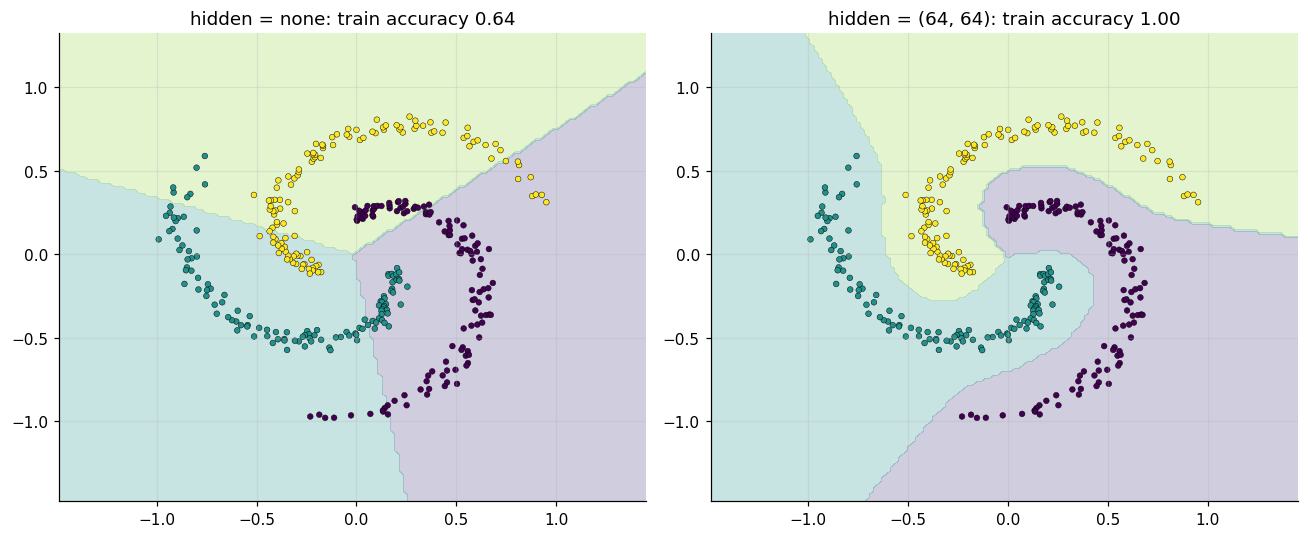

In [5]:
def spirals(n=120, k=3, noise=0.15, seed=0):
    rng = np.random.default_rng(seed); X, y = [], []
    for c in range(k):
        r = np.linspace(0.2, 1, n); t = np.linspace(c * 2 * np.pi / k, c * 2 * np.pi / k + 3.2, n) + rng.normal(scale=noise, size=n)
        X.append(np.c_[r * np.sin(t), r * np.cos(t)]); y += [c] * n
    return np.vstack(X), np.array(y)

Xs, ys = spirals()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, hs, ep in [(axes[0], (), 300), (axes[1], (64, 64), 600)]:
    net = NeuralNetClassifier(hidden_sizes=hs, lr=0.2, epochs=ep, batch_size=32, random_state=0).fit(Xs, ys)
    plot_boundary(ax, net, Xs, ys, cmap="viridis", n=140); ax.set_title(f"hidden = {hs or 'none'}: train accuracy {acc(net, Xs, ys):.2f}")
plt.tight_layout(); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

data = load_digits()
X = data.data / 16.0  # pixel values 0..16 -> 0..1
X_train, X_test, y_train, y_test = train_test_split(X, data.target, test_size=0.3, random_state=42)

ours = NeuralNetClassifier(hidden_sizes=(32,), lr=0.1, epochs=50, batch_size=32).fit(X_train, y_train)
theirs = MLPClassifier(hidden_layer_sizes=(32,), max_iter=300, random_state=0).fit(X_train, y_train)

acc_ours = (ours.predict(X_test) == y_test).mean()
acc_theirs = (theirs.predict(X_test) == y_test).mean()
print("digits test accuracy: ours=%.4f sklearn=%.4f" % (acc_ours, acc_theirs))
print("loss: %.4f -> %.4f over %d epochs" % (ours.loss_history_[0], ours.loss_history_[-1], len(ours.loss_history_)))
assert abs(acc_ours - acc_theirs) < 0.04

digits test accuracy: ours=0.9685 sklearn=0.9741
loss: 1.4785 -> 0.0501 over 50 epochs


/opt/anaconda3/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def test_backprop_matches_numerical_gradient():
    rng = np.random.default_rng(0)
    X = rng.normal(size=(8, 3))
    Y = np.eye(4)[rng.integers(0, 4, 8)]
    net = NeuralNetClassifier(hidden_sizes=(5, 4))
    net._init_params(3, 4, rng)
    # zero biases can put a pre-activation exactly on the ReLU kink, where finite differences lie
    net.b = [rng.normal(size=b.shape) for b in net.b]

    _, grad_W, grad_b = net._loss_and_grads(X, Y)
    eps = 1e-6
    for params, grads in ((net.W, grad_W), (net.b, grad_b)):
        for layer, grad in zip(params, grads):
            for idx in np.ndindex(layer.shape):
                original = layer[idx]
                layer[idx] = original + eps
                up = net._loss_and_grads(X, Y)[0]
                layer[idx] = original - eps
                down = net._loss_and_grads(X, Y)[0]
                layer[idx] = original
                assert abs((up - down) / (2 * eps) - grad[idx]) < 1e-6, idx


def test_learns_xor():
    # not linearly separable: needs the hidden layer
    X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]] * 25, dtype=float)
    y = np.array([0, 1, 1, 0] * 25)
    net = NeuralNetClassifier(hidden_sizes=(8,), lr=0.1, epochs=300, batch_size=16).fit(X, y)
    assert (net.predict(X) == y).all()


def test_iris_accuracy_and_loss_decreases():
    from sklearn.datasets import load_iris
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler

    data = load_iris()
    X_train, X_test, y_train, y_test = train_test_split(
        data.data, data.target, test_size=0.3, random_state=0
    )
    scaler = StandardScaler().fit(X_train)
    net = NeuralNetClassifier(hidden_sizes=(16,), epochs=100).fit(scaler.transform(X_train), y_train)
    assert net.loss_history_[-1] < net.loss_history_[0]
    assert (net.predict(scaler.transform(X_test)) == y_test).mean() > 0.9

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_backprop_matches_numerical_gradient
PASS test_learns_xor
PASS test_iris_accuracy_and_loss_decreases

all 3 tests passed


## Takeaways

- **What you built:** a fully-connected network, ReLU hidden layers, softmax output, cross-entropy loss, mini-batch SGD, and backprop by hand. The finite-difference gradient check in the tests is the standard way to verify backprop.
- **Why it works:** stacking linear maps with non-linearities lets it approximate (almost) any boundary; capacity is set by width and depth.
- **Pitfalls:** scale inputs, pick a sensible learning rate, watch for overfitting (more units and epochs memorise noise), initialisation matters (small random weights), and zero biases with ReLU can sit on the kink during gradient checks.
- **Interview line:** *"Forward: `h = ReLU(xW + b)`, `p = softmax(hW₂ + b₂)`; backward: `dz = p − y`, then `dW = hᵀdz` and propagate `dz Wᵀ` through the ReLU gate."*